# 3. BERT y comparación

**Responsable: Sara.**

El extractor BERT y su prueba con diez textos proceden del cuaderno original de Mónica.
Aquí se completan BERT congelado (medición del truncamiento, prueba y extracción), el
fine-tuning de BERT en los niveles 2 y 1, la tabla común de resultados, la incertidumbre
y el análisis de errores.

**Cómo ejecutarlo:**
- Las celdas de BERT y fine-tuning que necesitan GPU están desactivadas por defecto
  (`GENERAR_TODO`, `ENTRENAR_FT` y `EVALUAR_TEST` en `False`). Sus salidas proceden de
  ejecuciones en Colab con una GPU T4.
- Para repetir solo el análisis, que no necesita GPU, se ejecutan las tres primeras celdas
  de código (preparación, imports y datos) y después la sección **"Comparación de
  resultados"** y las de abajo.

## Preparación en Colab

Solo hace falta en Colab. La carpeta del proyecto debe estar en Google Drive con
`funciones.py`, `resultados/particiones.csv` y los dos Excel en `datos/`. Trabajar
desde Drive conserva `datos/cache/bert.joblib` cuando se cierra la sesión.
Una forma sencilla de prepararla es clonar el repositorio desde Colab en
`/content/drive/MyDrive` y subir después los Excel a `datos/`.
Fuera de Colab esta celda no hace nada.

In [2]:
import os
import sys

EN_COLAB = "google.colab" in sys.modules
if EN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    RUTA_PROYECTO = "/content/drive/MyDrive/proyecto-cordis"  # ajustar si está en otra carpeta
    os.chdir(RUTA_PROYECTO)
    if RUTA_PROYECTO not in sys.path:
        sys.path.insert(0, RUTA_PROYECTO)
print("Carpeta de trabajo:", os.getcwd())

Carpeta de trabajo: c:\Users\Sarar\OneDrive\Escritorio\UNIVERSIDAD\MASTER\1 año\1 cuatri\Tratamiento de datos\trabajo_final\proyecto-cordis


In [3]:
import json
import platform
import time
from datetime import datetime

import numpy as np
import pandas as pd
import torch
import transformers
from IPython.display import display
from tqdm.auto import tqdm
from transformers import AutoTokenizer, AutoModel

from funciones import (
    RESULTADOS, CACHE, SEMILLA,
    guardar_representacion, cargar_representacion,
)

np.random.seed(SEMILLA)
torch.manual_seed(SEMILLA)
print("Python:", platform.python_version(),
      "| torch:", torch.__version__,
      "| transformers:", transformers.__version__)

c:\venvs\cordis\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Python: 3.12.10 | torch: 2.15.0+cpu | transformers: 5.22.2


In [4]:
from funciones import cargar_datos, preparar_datos, cargar_o_crear_particiones

projects, scivoc = cargar_datos()
df = preparar_datos(projects, scivoc)
conjuntos = cargar_o_crear_particiones(df)  # comprueba IDs, etiquetas y orden con el CSV común
df_train = conjuntos["train"]
df_val = conjuntos["val"]
df_test = conjuntos["test"]
print({nombre: len(parte) for nombre, parte in conjuntos.items()})

{'train': 19189, 'val': 9594, 'test': 3199}


## BERT congelado

Usamos el resumen original, sin el preprocesamiento de TF-IDF: BERT tiene su propio
tokenizador WordPiece y aprovecha mayúsculas, puntuación y palabras vacías como contexto
(el modelo *uncased* pasa a minúsculas internamente).

- **Modelo:** `bert-base-uncased` (12 capas, vectores de 768 dimensiones).
- **Congelado:** modo evaluación y sin gradientes. Sus pesos no cambian; solo se usa
  como extractor de características. Esto es lo que lo distingue del fine-tuning.
- **Un vector por documento:** media de los vectores de la última capa de todos los
  tokens reales. La máscara de atención excluye el padding. La media incluye `[CLS]` y
  `[SEP]`, como en la base inicial. Se prefiere la media al vector de `[CLS]` porque, sin
  fine-tuning, `[CLS]` no está entrenado para resumir el documento.
- **Textos largos:** se truncan a 512 tokens (el máximo de BERT, incluidos `[CLS]` y `[SEP]`).
  Más abajo se mide a cuántos resúmenes afecta.

Esta primera carga descarga los pesos si todavía no están en el ordenador.

In [18]:
modelo_nombre = "bert-base-uncased"
MAX_LEN = 512
dispositivo = torch.device("cuda" if torch.cuda.is_available() else "cpu")
tokenizer = AutoTokenizer.from_pretrained(modelo_nombre)
modelo_bert = AutoModel.from_pretrained(modelo_nombre).to(dispositivo)
modelo_bert.requires_grad_(False)
modelo_bert.eval()
print("Dispositivo:", dispositivo,
      f"({torch.cuda.get_device_name(0)})" if dispositivo.type == "cuda" else "")

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Dispositivo: cuda (Tesla T4)


In [19]:
textos = {
    nombre: parte["summary"].fillna("").astype(str).tolist()
    for nombre, parte in conjuntos.items()
}
for nombre, lista in textos.items():
    print(nombre, len(lista))

train 19189
val 9594
test 3199


## ¿Cuántos resúmenes superan los 512 tokens?

Se tokeniza sin truncar para medir la longitud real en tokens WordPiece, contando
`[CLS]` y `[SEP]`. Es normal que aparezca el aviso *Token indices sequence length is
longer than the specified maximum*: aquí solo medimos y no se pasa nada al modelo.

In [20]:
def longitudes_en_tokens(lista, tamano_lote=1000):
    longitudes = []
    for i in range(0, len(lista), tamano_lote):
        codificados = tokenizer(lista[i:i + tamano_lote], truncation=False)
        longitudes.extend(len(ids) for ids in codificados["input_ids"])
    return np.array(longitudes)

longitudes = {nombre: longitudes_en_tokens(lista) for nombre, lista in textos.items()}

filas = []
for nombre, L in longitudes.items():
    truncados = L > MAX_LEN
    filas.append(dict(
        conjunto=nombre,
        resumenes=len(L),
        tokens_media=round(L.mean(), 1),
        tokens_mediana=int(np.median(L)),
        tokens_p95=int(np.percentile(L, 95)),
        tokens_max=int(L.max()),
        truncados=int(truncados.sum()),
        porcentaje_truncados=round(100 * truncados.mean(), 2),
        tokens_perdidos_media=round(float((L[truncados] - MAX_LEN).mean()), 1) if truncados.any() else 0.0,
    ))
tabla_truncamiento = pd.DataFrame(filas)
display(tabla_truncamiento)

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (625 > 512). Running this sequence through the model will result in indexing errors


,conjunto,resumenes,tokens_media,tokens_mediana,tokens_p95,tokens_max,truncados,porcentaje_truncados,tokens_perdidos_media
0,train,19189,354.5,366,422,838,15,0.08,105.2
1,val,9594,355.4,367,423,772,10,0.10,114.1
2,test,3199,354.6,366,423,538,3,0.09,14.7


**Interpretación (medido el 9/11/2026 en CPU, tabla anterior):** la mediana es de 366 tokens
y el 95 % de los resúmenes no llega a 425. Solo superan los 512 tokens 28 de los 31.982
resúmenes (15 en train, 10 en validación y 3 en test, un 0,09 %), y esos 28 conservan sus
primeros 512 tokens. El truncamiento es despreciable en este corpus: no compensa dividir los
textos largos en ventanas, y por el mismo motivo el fine-tuning también usa `max_length=512`.

In [21]:
def obtener_embeddings_bert(textos, batch_size=4, ordenar_por_longitud=True):
    """Devuelve una matriz (n, 768) en el MISMO orden que `textos`.

    Si ordenar_por_longitud=True, los lotes agrupan textos de longitud parecida para
    reducir el padding y acelerar la extracción. Cada vector se vuelve a escribir en
    su posición original, así que el orden de las filas no cambia.
    """
    n = len(textos)
    dimension = modelo_bert.config.hidden_size
    salida_total = np.zeros((n, dimension), dtype=np.float32)
    if n == 0:
        return salida_total
    orden = np.argsort([len(t) for t in textos], kind="stable") if ordenar_por_longitud else np.arange(n)

    for i in tqdm(range(0, n, batch_size), desc="Extrayendo BERT"):
        indices = orden[i:i + batch_size]
        entradas = tokenizer(
            [textos[j] for j in indices], padding=True, truncation=True,
            max_length=MAX_LEN, return_tensors="pt",
        )
        entradas = {k: v.to(dispositivo) for k, v in entradas.items()}
        with torch.no_grad():
            salida = modelo_bert(**entradas).last_hidden_state
            mascara = entradas["attention_mask"].unsqueeze(-1).to(salida.dtype)
            vector = (salida * mascara).sum(dim=1) / mascara.sum(dim=1).clamp(min=1)
        salida_total[indices] = vector.float().cpu().numpy()
    return salida_total

## Prueba con diez resúmenes

Antes de lanzar el corpus completo comprobamos:
1. que las dimensiones son (10, 768) y no hay valores no finitos;
2. que dos ejecuciones dan el mismo resultado;
3. que el padding no cambia el vector: procesar en lote o de uno en uno debe coincidir
   salvo ruido numérico (diferencias de 1e-4 o menos). Una diferencia grande indicaría
   que la máscara no está excluyendo el padding.

In [22]:
muestra = textos["train"][:10]
X_prueba_bert = obtener_embeddings_bert(muestra, batch_size=5)
X_repetida = obtener_embeddings_bert(muestra, batch_size=5)
X_uno_a_uno = obtener_embeddings_bert(muestra, batch_size=1)

print("Dimensiones de la prueba:", X_prueba_bert.shape)
print("Todos los valores son finitos:", bool(np.isfinite(X_prueba_bert).all()))
print("Diferencia máxima entre dos ejecuciones:", float(np.abs(X_prueba_bert - X_repetida).max()))
print("Diferencia máxima lote vs. uno a uno:", float(np.abs(X_prueba_bert - X_uno_a_uno).max()))

Extrayendo BERT:   0%|          | 0/2 [00:00<?, ?it/s]

Extrayendo BERT:   0%|          | 0/2 [00:00<?, ?it/s]

Extrayendo BERT:   0%|          | 0/10 [00:00<?, ?it/s]

Dimensiones de la prueba: (10, 768)
Todos los valores son finitos: True
Diferencia máxima entre dos ejecuciones: 0.0
Diferencia máxima lote vs. uno a uno: 7.152557373046875e-07


## Extracción completa

Cambiar `GENERAR_TODO` a `True` cuando se quiera ejecutar el corpus completo.
Los vectores se guardan fuera de GitHub en `datos/cache/bert.joblib` y se recargan
para comprobar que coinciden. Izan podrá cargarlos con `cargar_representacion("bert", conjuntos)`;
hay que pasarle el archivo por otro medio (Drive, por ejemplo).

La configuración realmente ejecutada (modelo, dispositivo, lote, tiempos, versiones y
truncamiento) se guarda en `resultados/bert_congelado_config.json`, que sí va a GitHub.

In [23]:
GENERAR_TODO = False

if GENERAR_TODO:
    batch_size = 32 if dispositivo.type == "cuda" else 4
    matrices_bert, minutos = {}, {}
    for nombre, lista in textos.items():
        inicio = time.time()
        matrices_bert[nombre] = obtener_embeddings_bert(lista, batch_size=batch_size)
        minutos[nombre] = round((time.time() - inicio) / 60, 2)
        assert matrices_bert[nombre].shape == (len(conjuntos[nombre]), modelo_bert.config.hidden_size)
        assert np.isfinite(matrices_bert[nombre]).all(), f"Valores no finitos en {nombre}"
        print(nombre, matrices_bert[nombre].shape, f"{minutos[nombre]} min")

    ruta = guardar_representacion("bert", matrices_bert, conjuntos)
    recargadas = cargar_representacion("bert", conjuntos)
    for nombre in matrices_bert:
        assert np.allclose(recargadas[nombre], matrices_bert[nombre]), nombre
    print("Vectores guardados y comprobados en:", ruta)

    registro = dict(
        fecha=datetime.now().isoformat(timespec="seconds"),
        modelo=modelo_nombre,
        congelado=True,
        pooling="media de la última capa sobre tokens con attention_mask=1 (incluye [CLS] y [SEP])",
        max_len=MAX_LEN,
        truncamiento="se conservan los primeros 512 tokens",
        texto="summary original, sin preprocesamiento",
        batch_size=batch_size,
        ordenado_por_longitud=True,
        dispositivo=torch.cuda.get_device_name(0) if dispositivo.type == "cuda" else "cpu",
        minutos=minutos,
        dimensiones={k: list(v.shape) for k, v in matrices_bert.items()},
        truncamiento_medido=tabla_truncamiento.to_dict(orient="records"),
        versiones=dict(python=platform.python_version(), torch=torch.__version__,
                       transformers=transformers.__version__),
        semilla=SEMILLA,
    )
    with open(RESULTADOS / "bert_congelado_config.json", "w", encoding="utf-8") as fichero:
        json.dump(registro, fichero, ensure_ascii=False, indent=2)
else:
    print("Extracción completa pendiente: activar GENERAR_TODO para ejecutarla.")

Extracción completa pendiente: activar GENERAR_TODO para ejecutarla.


## Fine-tuning de BERT

A diferencia de BERT congelado, aquí **se actualizan todos los pesos del Transformer** con
las etiquetas del problema. Se usa `AutoModelForSequenceClassification`: el mismo
`bert-base-uncased` más una capa lineal de clasificación sobre `[CLS]`, y todo se entrena junto.
Usar el mismo modelo base que en la versión congelada permite atribuir la diferencia
al hecho de adaptar los pesos, no a cambiar de modelo.

Decisiones:
- **Entrada:** el `summary` original, con las mismas particiones y `max_length=512`, porque
  solo se trunca el 0,09 % de los resúmenes. El padding se hace por lote (`DataCollatorWithPadding`).
- **Etiquetas:** los códigos EuroSciVoc se convierten en índices 0…K-1 con las clases de
  train, y el mapeo se guarda en `resultados/finetuning_mapeo_nivel{N}.json`.
- **Hiperparámetros:** dentro de los rangos habituales para BERT (Devlin et al., 2019:
  tasa de aprendizaje 2e-5 a 5e-5, lote 16 o 32, 2 a 4 épocas), con decaimiento de pesos 0,01
  y calentamiento del 10 % de los pasos. Se empieza con una sola configuración y se añaden
  más tasas solo si hay tiempo de GPU.
- **Selección con validación:** se evalúa al final de cada época, se guarda la época con
  mejor macro-F1 en validación y entre tasas se elige también por macro-F1 de validación.
  **El test no interviene.**
- **Solo con GPU:** en CPU tardaría días. Por eso `ENTRENAR_FT = False` por defecto y la
  celda se niega a entrenar sin GPU.
- `NIVEL = 2` es el proyecto básico. `NIVEL = 1` repite el experimento con las 6 raíces
  si el fine-tuning resulta la mejor configuración.

In [40]:
from pathlib import Path
from transformers import (
    AutoModelForSequenceClassification, DataCollatorWithPadding,
    Trainer, TrainingArguments, set_seed,
)
from funciones import evaluar

NIVEL = 2                    # 2 = proyecto básico (39 clases); 1 = repetición con 6 clases
ENTRENAR_FT = False          # True solo en Colab con GPU
TASAS_APRENDIZAJE = [3e-5]   # probadas: 2e-5 y 3e-5 (nivel 2); elegida 3e-5 por macro-F1 en validación
EPOCAS = 3
BATCH = 16
MAX_LEN_FT = 512
CARPETA_MODELOS = Path("modelos")                  # pesos fuera de GitHub (.gitignore)
CARPETA_PREDICCIONES = RESULTADOS / "predicciones"
CARPETA_GRAFICAS = RESULTADOS / "graficas"
for carpeta in (CARPETA_MODELOS, CARPETA_PREDICCIONES, CARPETA_GRAFICAS):
    carpeta.mkdir(parents=True, exist_ok=True)

# Mapeo código EuroSciVoc -> índice consecutivo, aprendido con train
columna = f"label_nivel{NIVEL}"
clases = sorted(int(c) for c in conjuntos["train"][columna].unique())
for nombre in ("val", "test"):
    assert set(conjuntos[nombre][columna]) <= set(clases), f"Hay clases de {nombre} que no están en train"
codigo_a_indice = {c: i for i, c in enumerate(clases)}
indice_a_codigo = {i: c for c, i in codigo_a_indice.items()}
y_ft = {nombre: parte[columna].map(codigo_a_indice).to_numpy() for nombre, parte in conjuntos.items()}

with open(RESULTADOS / f"finetuning_mapeo_nivel{NIVEL}.json", "w", encoding="utf-8") as fichero:
    json.dump({"nivel": NIVEL, "indice_a_codigo": indice_a_codigo}, fichero, indent=2)
print(f"Nivel {NIVEL}: {len(clases)} clases")

Nivel 1: 6 clases


In [41]:
class ResumenesDataset(torch.utils.data.Dataset):
    """Resúmenes tokenizados sin padding; el padding lo añade el collator en cada lote."""
    def __init__(self, lista_textos, etiquetas):
        self.codificados = tokenizer(lista_textos, truncation=True, max_length=MAX_LEN_FT)
        self.etiquetas = etiquetas
    def __len__(self):
        return len(self.etiquetas)
    def __getitem__(self, i):
        item = {clave: valores[i] for clave, valores in self.codificados.items()}
        item["labels"] = int(self.etiquetas[i])
        return item

def metricas_ft(eval_pred):
    """Accuracy y macro-F1 sobre las K clases (las mismas que el resto del grupo)."""
    prediccion = np.argmax(eval_pred.predictions, axis=1)
    return evaluar(eval_pred.label_ids, prediccion, clases=list(range(len(clases))))

def guardar_metricas_sara(experimento, representacion, modelo, nivel, conjunto, metricas):
    """Mismo esquema que guardar_metricas, pero en resultados/metricas_sara.csv."""
    ruta = RESULTADOS / "metricas_sara.csv"
    fila = dict(experimento=experimento, representacion=representacion, modelo=modelo,
                nivel=nivel, conjunto=conjunto, **metricas)
    tabla = pd.read_csv(ruta) if ruta.exists() else pd.DataFrame(columns=list(fila))
    misma = (tabla["experimento"] == experimento) & (tabla["nivel"] == nivel) & (tabla["conjunto"] == conjunto)
    tabla = pd.concat([tabla.loc[~misma], pd.DataFrame([fila])], ignore_index=True)
    tabla.to_csv(ruta, index=False)
    return tabla

def guardar_predicciones(nombre_experimento, conjunto, y_pred_indices):
    """CSV con projectID, nivel, conjunto, etiqueta real y predicha (códigos EuroSciVoc)."""
    parte = conjuntos[conjunto]
    tabla = pd.DataFrame({
        "projectID": parte["projectID"].to_numpy(),
        "nivel": NIVEL,
        "conjunto": conjunto,
        "y_real": parte[columna].to_numpy(),
        "y_pred": [indice_a_codigo[int(i)] for i in y_pred_indices],
    })
    ruta = CARPETA_PREDICCIONES / f"{nombre_experimento}_{conjunto}.csv"
    tabla.to_csv(ruta, index=False)
    return ruta

### Entrenamiento y selección con validación

Para cada tasa de aprendizaje se entrena, se guarda la mejor época según macro-F1 en
validación, sus predicciones de validación, sus métricas y el historial de entrenamiento.
Los pesos del mejor modelo se guardan en `modelos/` (fuera de GitHub) para poder evaluar
el test más adelante sin volver a entrenar.

In [42]:
if ENTRENAR_FT:
    assert torch.cuda.is_available(), "El fine-tuning necesita GPU: ejecútalo en Colab con T4."
    datasets_ft = {nombre: ResumenesDataset(textos[nombre], y_ft[nombre]) for nombre in ("train", "val")}
    pasos_totales = int(np.ceil(len(datasets_ft["train"]) / BATCH)) * EPOCAS
    busqueda = []

    for lr in TASAS_APRENDIZAJE:
        set_seed(SEMILLA)
        nombre_exp = f"finetuning_bert_n{NIVEL}_lr{lr:g}"
        modelo_ft = AutoModelForSequenceClassification.from_pretrained(
            modelo_nombre, num_labels=len(clases),
            id2label={i: str(c) for i, c in indice_a_codigo.items()},
            label2id={str(c): i for i, c in indice_a_codigo.items()},
        )
        argumentos = TrainingArguments(
            output_dir=("/content/checkpoints/" if EN_COLAB else "checkpoints/") + nombre_exp,
            num_train_epochs=EPOCAS,
            learning_rate=lr,
            per_device_train_batch_size=BATCH,
            per_device_eval_batch_size=64,
            weight_decay=0.01,
            warmup_steps=int(0.1 * pasos_totales),
            eval_strategy="epoch",
            save_strategy="epoch",
            save_total_limit=1,
            load_best_model_at_end=True,
            metric_for_best_model="macro_f1",
            greater_is_better=True,
            logging_steps=50,
            fp16=True,
            seed=SEMILLA,
            report_to="none",
        )
        entrenador = Trainer(
            model=modelo_ft, args=argumentos,
            train_dataset=datasets_ft["train"], eval_dataset=datasets_ft["val"],
            data_collator=DataCollatorWithPadding(tokenizer),
            compute_metrics=metricas_ft,
        )
        inicio = time.time()
        entrenador.train()
        minutos = round((time.time() - inicio) / 60, 1)

        # Mejor época (ya cargada por load_best_model_at_end) evaluada en validación
        salida_val = entrenador.predict(datasets_ft["val"])
        pred_val = np.argmax(salida_val.predictions, axis=1)
        m_val = evaluar(conjuntos["val"][columna], [indice_a_codigo[int(i)] for i in pred_val], clases=clases)
        guardar_predicciones(nombre_exp, "val", pred_val)
        guardar_metricas_sara(nombre_exp, "texto original", "BERT fine-tuning", NIVEL, "val", m_val)

        entrenador.save_model(CARPETA_MODELOS / nombre_exp)
        tokenizer.save_pretrained(CARPETA_MODELOS / nombre_exp)
        with open(RESULTADOS / f"{nombre_exp}_historial.json", "w", encoding="utf-8") as fichero:
            json.dump(entrenador.state.log_history, fichero, indent=1)

        busqueda.append(dict(
            experimento=nombre_exp, nivel=NIVEL, learning_rate=lr, epocas=EPOCAS, batch=BATCH,
            max_len=MAX_LEN_FT, mejor_checkpoint=entrenador.state.best_model_checkpoint,
            val_accuracy=m_val["accuracy"], val_macro_f1=m_val["macro_f1"], minutos=minutos,
            gpu=torch.cuda.get_device_name(0), torch=torch.__version__,
            transformers=transformers.__version__, semilla=SEMILLA,
        ))
        print(nombre_exp, m_val, f"{minutos} min")
        del entrenador, modelo_ft
        torch.cuda.empty_cache()

    tabla_busqueda = pd.DataFrame(busqueda)
    ruta_busqueda = RESULTADOS / f"finetuning_busqueda_nivel{NIVEL}.csv"
    if ruta_busqueda.exists():  # conservar ejecuciones anteriores con otras tasas
        anteriores = pd.read_csv(ruta_busqueda)
        tabla_busqueda = pd.concat([anteriores[~anteriores["experimento"].isin(tabla_busqueda["experimento"])],
                                    tabla_busqueda], ignore_index=True)
    tabla_busqueda.to_csv(ruta_busqueda, index=False)
    display(tabla_busqueda)
else:
    print("Fine-tuning desactivado: poner ENTRENAR_FT = True en Colab con GPU.")

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch,Training Loss,Validation Loss,Accuracy,Macro F1
1,0.797420,0.808791,0.688660,0.640825
2,0.698093,0.762156,0.712320,0.663786
3,0.548365,0.795934,0.714926,0.675820


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

[transformers] There were missing keys in the checkpoint model loaded: ['bert.embeddings.LayerNorm.weight', 'bert.embeddings.LayerNorm.bias', 'bert.encoder.layer.0.attention.output.LayerNorm.weight', 'bert.encoder.layer.0.attention.output.LayerNorm.bias', 'bert.encoder.layer.0.output.LayerNorm.weight', 'bert.encoder.layer.0.output.LayerNorm.bias', 'bert.encoder.layer.1.attention.output.LayerNorm.weight', 'bert.encoder.layer.1.attention.output.LayerNorm.bias', 'bert.encoder.layer.1.output.LayerNorm.weight', 'bert.encoder.layer.1.output.LayerNorm.bias', 'bert.encoder.layer.2.attention.output.LayerNorm.weight', 'bert.encoder.layer.2.attention.output.LayerNorm.bias', 'bert.encoder.layer.2.output.LayerNorm.weight', 'bert.encoder.layer.2.output.LayerNorm.bias', 'bert.encoder.layer.3.attention.output.LayerNorm.weight', 'bert.encoder.layer.3.attention.output.LayerNorm.bias', 'bert.encoder.layer.3.output.LayerNorm.weight', 'bert.encoder.layer.3.output.LayerNorm.bias', 'bert.encoder.layer.4.atte

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

finetuning_bert_n1_lr3e-05 {'accuracy': 0.7149259954138003, 'macro_f1': 0.6758201376710803} 34.3 min


,experimento,nivel,learning_rate,epocas,batch,max_len,mejor_checkpoint,val_accuracy,val_macro_f1,minutos,gpu,torch,transformers,semilla
0,finetuning_bert_n1_lr3e-05,1,0.00003,3,16,512,/content/checkpoints/finetuning_bert_n1_lr3e-0...,0.714926,0.67582,34.3,Tesla T4,2.14.1+cu130,5.22.1,42


### Curvas de entrenamiento y validación

Se dibujan desde el historial guardado, así que se pueden regenerar sin volver a entrenar.
La pérdida de entrenamiento se registra cada 50 pasos; la de validación y el macro-F1, al
final de cada época. Si la pérdida de validación sube mientras la de entrenamiento baja,
hay sobreajuste, y la mejor época elegida debería ser anterior.

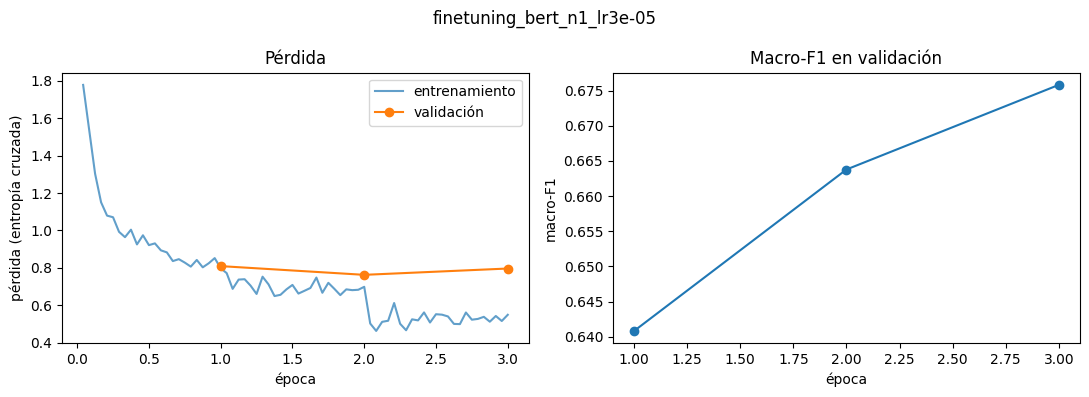

In [43]:
historiales = sorted(RESULTADOS.glob(f"finetuning_bert_n{NIVEL}_lr*_historial.json"))
if not historiales:
    print("Todavía no hay historiales de fine-tuning.")
else:
    import matplotlib.pyplot as plt
    for ruta in historiales:
        historial = json.load(open(ruta, encoding="utf-8"))
        entrenamiento = [(h["epoch"], h["loss"]) for h in historial if "loss" in h]
        evaluacion = [(h["epoch"], h["eval_loss"], h["eval_macro_f1"]) for h in historial if "eval_loss" in h]
        fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
        ax1.plot(*zip(*entrenamiento), label="entrenamiento", alpha=0.7)
        ax1.plot([e for e, _, _ in evaluacion], [l for _, l, _ in evaluacion], "o-", label="validación")
        ax1.set(xlabel="época", ylabel="pérdida (entropía cruzada)", title="Pérdida")
        ax1.legend()
        ax2.plot([e for e, _, _ in evaluacion], [f for _, _, f in evaluacion], "o-")
        ax2.set(xlabel="época", ylabel="macro-F1", title="Macro-F1 en validación")
        nombre_exp = ruta.stem.replace("_historial", "")
        fig.suptitle(nombre_exp)
        fig.tight_layout()
        fig.savefig(CARPETA_GRAFICAS / f"{nombre_exp}_curvas.png", dpi=150)
        plt.show()

### Evaluación final en test

**Ejecutar solo cuando el grupo haya cerrado todas las decisiones** (objetivo: 30 de
noviembre). Usa la configuración con mejor macro-F1 en validación, sin volver a entrenar.

In [44]:
EVALUAR_TEST = False

if EVALUAR_TEST:
    busqueda = pd.read_csv(RESULTADOS / f"finetuning_busqueda_nivel{NIVEL}.csv")
    mejor = busqueda.sort_values("val_macro_f1", ascending=False).iloc[0]
    print("Configuración elegida con validación:", mejor["experimento"])
    modelo_final = AutoModelForSequenceClassification.from_pretrained(CARPETA_MODELOS / mejor["experimento"])
    evaluador = Trainer(
        model=modelo_final,
        args=TrainingArguments(output_dir="checkpoints/test", per_device_eval_batch_size=64, report_to="none"),
        data_collator=DataCollatorWithPadding(tokenizer),
    )
    salida_test = evaluador.predict(ResumenesDataset(textos["test"], y_ft["test"]))
    pred_test = np.argmax(salida_test.predictions, axis=1)
    m_test = evaluar(conjuntos["test"][columna], [indice_a_codigo[int(i)] for i in pred_test], clases=clases)
    guardar_predicciones(mejor["experimento"], "test", pred_test)
    guardar_metricas_sara(mejor["experimento"], "texto original", "BERT fine-tuning", NIVEL, "test", m_test)
    print(m_test)
else:
    print("Evaluación en test pendiente: se hará al cerrar las decisiones.")

Evaluación en test pendiente: se hará al cerrar las decisiones.


## Comparación de resultados

A partir de aquí no hace falta GPU: todo se calcula con los CSV de `resultados/`.

**Conjunto analizado.** Mientras el grupo ajusta modelos se trabaja con **validación**.
Cuando las decisiones estén cerradas y existan las predicciones de test, se cambia
`CONJUNTO = "test"` y se vuelven a ejecutar estas celdas para el informe final. Nada de lo
que se calcula aquí sirve para elegir modelos con el test.

**Tabla común.** Se reúnen `metricas_monica.csv`, `metricas_izan.csv` y `metricas_sara.csv`
(las que existan), las filas que ya hubiera en `metricas.csv` y el baseline de clase
mayoritaria, y se guarda todo en `resultados/metricas.csv`. Si falta el archivo de alguien,
sus modelos simplemente no aparecen: no se inventa ningún valor.

In [5]:
from sklearn.metrics import classification_report, confusion_matrix, f1_score, accuracy_score
from funciones import evaluar   # también se importa en el fine-tuning; aquí para que el análisis funcione solo

CONJUNTO = "val"            # "test" solo para el informe final, con las decisiones cerradas
B_BOOTSTRAP = 1000          # remuestreos del bootstrap
CARPETA_PREDICCIONES = RESULTADOS / "predicciones"
CARPETA_GRAFICAS = RESULTADOS / "graficas"
CARPETA_GRAFICAS.mkdir(parents=True, exist_ok=True)

# Jerarquía EuroSciVoc (misma regla que preparar_datos) y nombres de las categorías
catalogo = scivoc.dropna(subset=["code"])
jerarquia = {int(f.code): [int(x) for x in str(f.full_code).split("/") if x] for f in catalogo.itertuples()}
nombre_categoria = {int(c): t for c, t in zip(catalogo["code"], catalogo["title"])}
raiz_de = {codigo: niveles[0] for codigo, niveles in jerarquia.items()}

# Clases de referencia por nivel: las de train (las mismas para todos los modelos)
clases_nivel = {n: sorted(int(c) for c in conjuntos["train"][f"label_nivel{n}"].unique()) for n in (1, 2)}

# Todas las categorías válidas de cada proyecto (no solo la primera), por nivel
def categorias_validas(codigos, nivel):
    salida = set()
    for codigo in codigos:
        niveles = jerarquia.get(int(codigo), [])
        if len(niveles) >= 2:          # misma condición que la etiqueta: el código llega a nivel 2
            salida.add(niveles[nivel - 1])
    return salida

info_proyectos = pd.concat(conjuntos.values(), ignore_index=True).set_index("projectID")
validas = {n: info_proyectos["euroSciVocCode"].map(lambda c, n=n: categorias_validas(c, n)) for n in (1, 2)}
print({n: len(c) for n, c in clases_nivel.items()}, "clases por nivel")

{1: 6, 2: 39} clases por nivel


In [6]:
# Baseline: clase mayoritaria aprendida en train, con los mismos IDs que el resto de modelos
def guardar_baseline(nivel, conjunto):
    columna_nivel = f"label_nivel{nivel}"
    mayoritaria = int(conjuntos["train"][columna_nivel].mode()[0])
    parte = conjuntos[conjunto]
    tabla = pd.DataFrame({"projectID": parte["projectID"], "nivel": nivel, "conjunto": conjunto,
                          "y_real": parte[columna_nivel], "y_pred": mayoritaria})
    tabla.to_csv(CARPETA_PREDICCIONES / f"baseline_mayoritaria_n{nivel}_{conjunto}.csv", index=False)
    return dict(experimento=f"baseline_mayoritaria_n{nivel}", representacion="ninguna",
                modelo="clase mayoritaria", nivel=nivel, conjunto=conjunto,
                **evaluar(tabla["y_real"], tabla["y_pred"], clases=clases_nivel[nivel]))

filas_baseline = [guardar_baseline(n, c) for n in (1, 2) for c in ("val", "test")]

# Tabla común: archivos personales + metricas.csv existente + baseline (sin duplicar experimentos)
fuentes = []
for persona in ("monica", "izan", "sara"):
    ruta = RESULTADOS / f"metricas_{persona}.csv"
    if ruta.exists():
        fuentes.append(pd.read_csv(ruta).assign(origen=persona))
    else:
        print(f"Aún no existe {ruta.name}: sus modelos no aparecen en la tabla.")
ruta_comun = RESULTADOS / "metricas.csv"
if ruta_comun.exists():
    previas = pd.read_csv(ruta_comun)
    if not previas.empty:
        fuentes.append(previas.assign(origen=previas.get("origen", "metricas.csv")))
fuentes.append(pd.DataFrame(filas_baseline).assign(origen="baseline (cuaderno 03)"))

clave = ["experimento", "nivel", "conjunto"]
metricas_todas = (pd.concat([f for f in fuentes if not f.empty], ignore_index=True)
                  .drop_duplicates(subset=clave, keep="first")
                  .sort_values(["nivel", "conjunto", "macro_f1"], ascending=[False, True, False]))
metricas_todas.to_csv(ruta_comun, index=False)
display(metricas_todas[metricas_todas["conjunto"] == CONJUNTO].round(4))

Aún no existe metricas_monica.csv: sus modelos no aparecen en la tabla.
Aún no existe metricas_izan.csv: sus modelos no aparecen en la tabla.


,experimento,representacion,modelo,nivel,conjunto,accuracy,macro_f1,origen
1,finetuning_bert_n2_lr3e-05,texto original,BERT fine-tuning,2,val,0.5849,0.3696,sara
0,finetuning_bert_n2_lr2e-05,texto original,BERT fine-tuning,2,val,0.5725,0.3381,sara
5,baseline_mayoritaria_n2,ninguna,clase mayoritaria,2,val,0.1083,0.0050,baseline (cuaderno 03)
2,finetuning_bert_n1_lr3e-05,texto original,BERT fine-tuning,1,val,0.7149,0.6758,sara
3,baseline_mayoritaria_n1,ninguna,clase mayoritaria,1,val,0.3916,0.0938,baseline (cuaderno 03)


## Incertidumbre: qué diferencias se pueden interpretar

Con un único conjunto de evaluación, cada métrica tiene una incertidumbre debida a qué
proyectos han caído en él. Se estima con **bootstrap**: se remuestrean con reemplazo los
proyectos del conjunto 1.000 veces y se recalcula la métrica. El intervalo del 95 % va del
percentil 2,5 al 97,5.

**Criterio para comparar dos modelos.** Se usa un **bootstrap pareado**: en cada remuestreo
se toman *los mismos proyectos* para los dos modelos (unidos por `projectID`) y se calcula la
diferencia. Solo se considera que un modelo es mejor si el intervalo del 95 % de la
diferencia **no incluye el 0**. Si lo incluye, la diferencia está dentro del ruido y se
informa como empate.

Como orientación, para la accuracy el error típico es aproximadamente √(p(1−p)/n). La tabla
siguiente da la mitad del intervalo del 95 % para los tamaños de validación y test. Para
el macro-F1 el ruido es mayor, porque las clases pequeñas tienen muy pocos ejemplos.

In [7]:
def orden_aprox(p, n):
    return 1.96 * np.sqrt(p * (1 - p) / n)

display(pd.DataFrame([
    {"conjunto": c, "n": len(conjuntos[c]),
     **{f"±IC95 si accuracy={p}": round(orden_aprox(p, len(conjuntos[c])), 4) for p in (0.3, 0.5, 0.6)}}
    for c in ("val", "test")
]))

def cargar_predicciones(ruta):
    tabla = pd.read_csv(ruta)
    assert tabla["projectID"].is_unique, f"IDs repetidos en {ruta.name}"
    return tabla

def bootstrap_metricas(tabla, clases, B=B_BOOTSTRAP, semilla=SEMILLA):
    rng = np.random.default_rng(semilla)
    y, p = tabla["y_real"].to_numpy(), tabla["y_pred"].to_numpy()
    acc, f1 = [], []
    for _ in range(B):
        i = rng.integers(0, len(y), len(y))
        acc.append(accuracy_score(y[i], p[i]))
        f1.append(f1_score(y[i], p[i], labels=clases, average="macro", zero_division=0))
    return dict(accuracy=accuracy_score(y, p),
                accuracy_ic=(np.percentile(acc, 2.5), np.percentile(acc, 97.5)),
                macro_f1=f1_score(y, p, labels=clases, average="macro", zero_division=0),
                macro_f1_ic=(np.percentile(f1, 2.5), np.percentile(f1, 97.5)))

def bootstrap_diferencia(tabla_a, tabla_b, clases, B=B_BOOTSTRAP, semilla=SEMILLA):
    """Diferencia A − B con los mismos proyectos en cada remuestreo (unidos por projectID)."""
    unidas = tabla_a.merge(tabla_b, on="projectID", suffixes=("_a", "_b"))
    assert len(unidas) == len(tabla_a) == len(tabla_b), "Los dos modelos no tienen los mismos proyectos"
    assert (unidas["y_real_a"] == unidas["y_real_b"]).all(), "Las etiquetas reales no coinciden"
    y = unidas["y_real_a"].to_numpy()
    pa, pb = unidas["y_pred_a"].to_numpy(), unidas["y_pred_b"].to_numpy()
    rng = np.random.default_rng(semilla)
    d_acc, d_f1 = [], []
    for _ in range(B):
        i = rng.integers(0, len(y), len(y))
        d_acc.append(accuracy_score(y[i], pa[i]) - accuracy_score(y[i], pb[i]))
        d_f1.append(f1_score(y[i], pa[i], labels=clases, average="macro", zero_division=0)
                    - f1_score(y[i], pb[i], labels=clases, average="macro", zero_division=0))
    salida = {}
    for nombre, valores in (("accuracy", d_acc), ("macro_f1", d_f1)):
        bajo, alto = np.percentile(valores, 2.5), np.percentile(valores, 97.5)
        salida[f"dif_{nombre}"] = float(np.mean(valores))
        salida[f"dif_{nombre}_ic"] = (round(float(bajo), 4), round(float(alto), 4))
        salida[f"{nombre}_significativa"] = bool(bajo > 0 or alto < 0)
    return salida

,conjunto,n,±IC95 si accuracy=0.3,±IC95 si accuracy=0.5,±IC95 si accuracy=0.6
0,val,9594,0.0092,0.0100,0.0098
1,test,3199,0.0159,0.0173,0.0170


In [8]:
# Intervalos de todos los modelos con predicciones guardadas para CONJUNTO
predicciones = {}
for ruta in sorted(CARPETA_PREDICCIONES.glob(f"*_{CONJUNTO}.csv")):
    tabla = cargar_predicciones(ruta)
    nivel = int(tabla["nivel"].iloc[0])
    predicciones[(ruta.stem.removesuffix(f"_{CONJUNTO}"), nivel)] = tabla

filas = []
for (experimento, nivel), tabla in predicciones.items():
    r = bootstrap_metricas(tabla, clases_nivel[nivel])
    filas.append(dict(experimento=experimento, nivel=nivel, n=len(tabla),
                      accuracy=round(float(r["accuracy"]), 4), accuracy_ic95=tuple(round(float(x), 4) for x in r["accuracy_ic"]),
                      macro_f1=round(float(r["macro_f1"]), 4), macro_f1_ic95=tuple(round(float(x), 4) for x in r["macro_f1_ic"])))
tabla_ic = pd.DataFrame(filas).sort_values(["nivel", "macro_f1"], ascending=[False, False])
tabla_ic.to_csv(RESULTADOS / f"intervalos_{CONJUNTO}.csv", index=False)
display(tabla_ic)

,experimento,nivel,n,accuracy,accuracy_ic95,macro_f1,macro_f1_ic95
4,finetuning_bert_n2_lr3e-05,2,9594,0.5849,"(0.5747, 0.594)",0.3696,"(0.3577, 0.3801)"
3,finetuning_bert_n2_lr2e-05,2,9594,0.5725,"(0.5625, 0.5813)",0.3381,"(0.3275, 0.347)"
1,baseline_mayoritaria_n2,2,9594,0.1083,"(0.1019, 0.1144)",0.0050,"(0.0047, 0.0053)"
2,finetuning_bert_n1_lr3e-05,1,9594,0.7149,"(0.7056, 0.724)",0.6758,"(0.6618, 0.6888)"
0,baseline_mayoritaria_n1,1,9594,0.3916,"(0.382, 0.4021)",0.0938,"(0.0921, 0.0956)"


In [9]:
# Comparaciones pareadas dentro de cada nivel: cada modelo frente al mejor de ese nivel
filas = []
for nivel in (2, 1):
    del_nivel = {e: t for (e, n), t in predicciones.items() if n == nivel}
    if len(del_nivel) < 2:
        continue
    mejor = max(del_nivel, key=lambda e: f1_score(del_nivel[e]["y_real"], del_nivel[e]["y_pred"],
                                                 labels=clases_nivel[nivel], average="macro", zero_division=0))
    for otro in del_nivel:
        if otro != mejor:
            filas.append(dict(nivel=nivel, modelo_a=mejor, modelo_b=otro,
                              **bootstrap_diferencia(del_nivel[mejor], del_nivel[otro], clases_nivel[nivel])))
tabla_diferencias = pd.DataFrame(filas)
if not tabla_diferencias.empty:
    tabla_diferencias.to_csv(RESULTADOS / f"diferencias_{CONJUNTO}.csv", index=False)
    display(tabla_diferencias)
else:
    print("Hace falta más de un modelo por nivel para comparar.")

,nivel,modelo_a,modelo_b,dif_accuracy,dif_accuracy_ic,accuracy_significativa,dif_macro_f1,dif_macro_f1_ic,macro_f1_significativa
0,2,finetuning_bert_n2_lr3e-05,baseline_mayoritaria_n2,0.476189,"(0.465, 0.488)",True,0.363738,"(0.3527, 0.375)",True
1,2,finetuning_bert_n2_lr3e-05,finetuning_bert_n2_lr2e-05,0.012458,"(0.0073, 0.0176)",True,0.031275,"(0.0228, 0.0402)",True
2,1,finetuning_bert_n1_lr3e-05,baseline_mayoritaria_n1,0.323138,"(0.3096, 0.336)",True,0.581784,"(0.5676, 0.5953)",True


## Ranking de representaciones por nivel

El enunciado pregunta si el orden de TF-IDF, Word2Vec y BERT cambia al pasar de 39 a 6
clases. Se toma, para cada representación y nivel, el mejor macro-F1 disponible en
`CONJUNTO`. La tabla estará completa cuando Izan guarde sus resultados de los dos niveles.
Antes de interpretar un cambio de orden, hay que comprobar con las comparaciones pareadas
que las diferencias implicadas son significativas.

In [10]:
del_conjunto = metricas_todas[(metricas_todas["conjunto"] == CONJUNTO) & (metricas_todas["modelo"] != "clase mayoritaria")]
ranking = (del_conjunto.groupby(["representacion", "nivel"])["macro_f1"].max()
           .unstack("nivel").rename(columns=lambda n: f"macro_f1_nivel{n}"))
for columna_nivel in ranking.columns:
    ranking[columna_nivel.replace("macro_f1", "puesto")] = ranking[columna_nivel].rank(ascending=False, method="min")
display(ranking.sort_values(ranking.columns[0], ascending=False))

nivel,macro_f1_nivel1,macro_f1_nivel2,puesto_nivel1,puesto_nivel2
representacion,,,,
texto original,0.67582,0.369561,1.0,1.0


## Análisis de errores

Se analiza el mejor modelo de cada nivel según macro-F1 en `CONJUNTO`, o el experimento
que se indique en `EXPERIMENTO_ANALISIS`.

1. **Por clase:** precisión, exhaustividad (recall), F1 y número de ejemplos. Las clases
   con muy pocos ejemplos dan F1 muy inestables.
2. **Matriz de confusión completa**, normalizada por filas: cada fila suma 1 y muestra a
   dónde van los proyectos de una categoría real.
3. **¿Categorías hermanas?** En nivel 2, porcentaje de errores en los que la predicción
   comparte raíz de nivel 1 con la etiqueta real. Se compara con lo que se esperaría si el
   modelo eligiera la categoría equivocada al azar, con la frecuencia con que predice cada
   categoría.
4. **¿Era otra categoría del proyecto?** Porcentaje de errores en los que la predicción es
   otra de las categorías válidas del proyecto, descartada al quedarnos solo con la primera.
   Esos errores se deben a la ambigüedad de la etiqueta, no a un fallo real del modelo.


=== Nivel 2: finetuning_bert_n2_lr3e-05 ===


,precision,recall,f1-score,ejemplos
41 other medical sciences,0.000,0.000,0.000,2
65 chemical engineering,0.000,0.000,0.000,39
61 industrial biotechnology,0.000,0.000,0.000,29
57 medical engineering,0.000,0.000,0.000,39
79 agricultural biotechnology,0.000,0.000,0.000,10
87 veterinary sciences,0.000,0.000,0.000,7
71 environmental biotechnology,0.000,0.000,0.000,9
103 media and communications,0.000,0.000,0.000,12
115 other humanities,0.000,0.000,0.000,20
83 animal and dairy science,0.500,0.050,0.091,40


Matplotlib is building the font cache; this may take a moment.


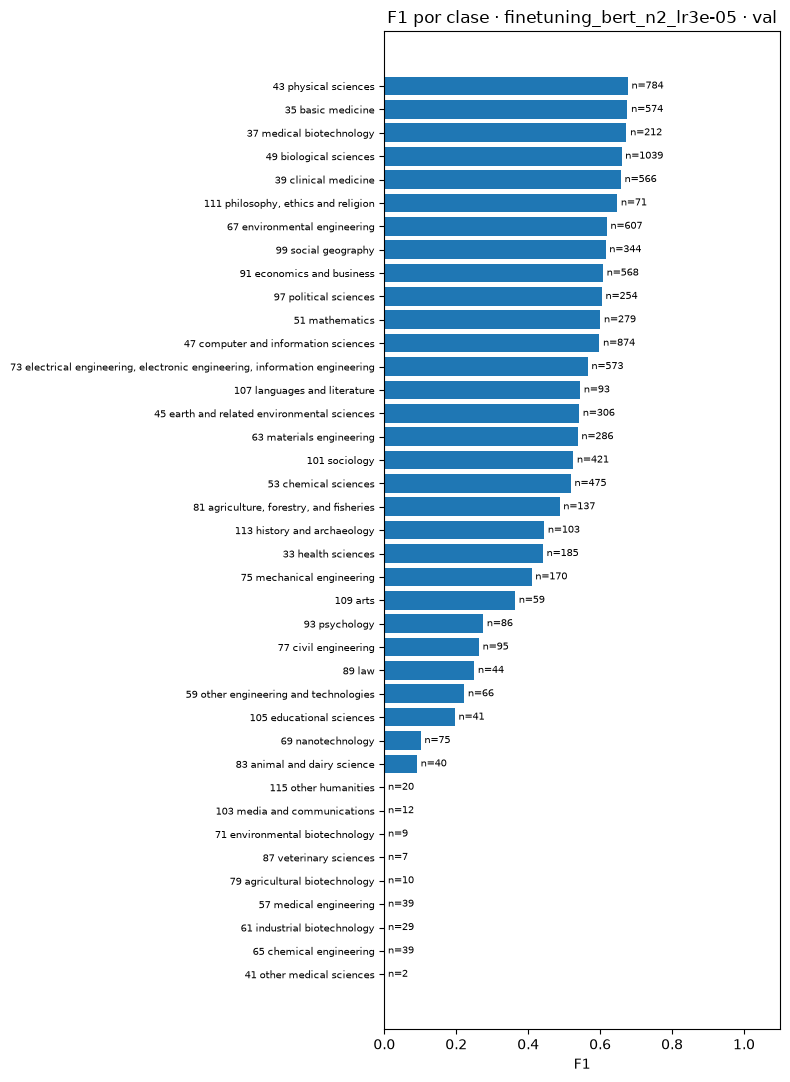

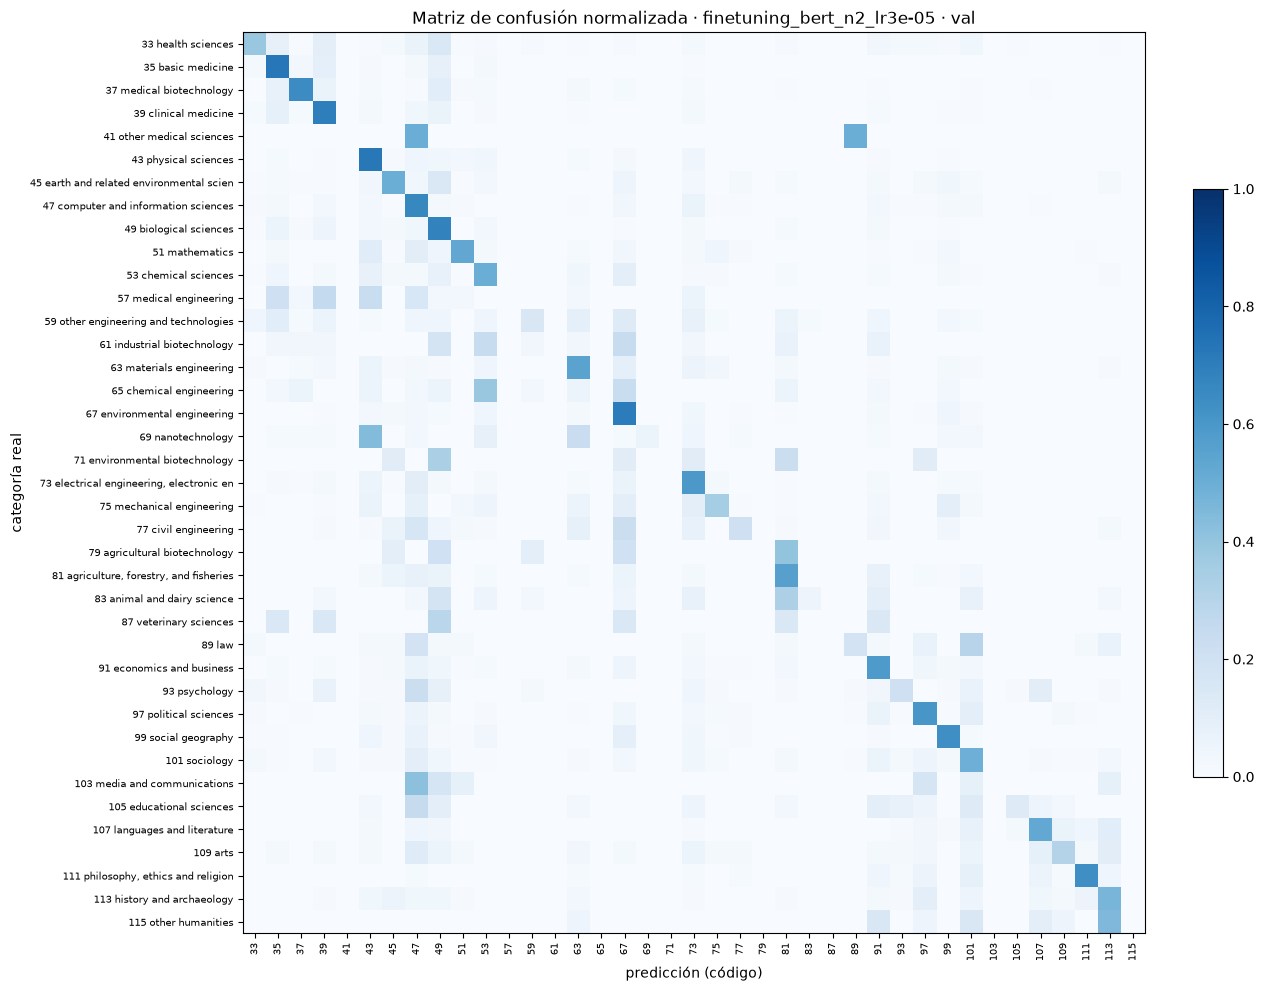

,finetuning_bert_n2_lr3e-05
proyectos,9594
errores,3982
% errores que son otra categoría válida del proyecto,55.1
accuracy estricta,0.5849
accuracy si contara cualquier categoría válida del proyecto,0.8138
% errores entre categorías hermanas (misma raíz),33.8
% esperado si el error fuese al azar,21.1


,casos,real,predicha,hermanas
135,63,49 biological sciences,35 basic medicine,False
305,60,"73 electrical engineering, electronic engineer...",47 computer and information sciences,False
120,56,47 computer and information sciences,"73 electrical engineering, electronic engineer...",False
23,52,35 basic medicine,39 clinical medicine,True
137,49,49 biological sciences,39 clinical medicine,False
50,48,39 clinical medicine,35 basic medicine,True
183,47,53 chemical sciences,67 environmental engineering,False
26,45,35 basic medicine,49 biological sciences,False
94,45,45 earth and related environmental sciences,49 biological sciences,True
480,40,101 sociology,47 computer and information sciences,False



=== Nivel 1: finetuning_bert_n1_lr3e-05 ===


,precision,recall,f1-score,ejemplos
27 agricultural sciences,0.500,0.557,0.527,194
31 humanities,0.701,0.630,0.664,346
25 engineering and technology,0.660,0.697,0.678,1988
29 social sciences,0.710,0.664,0.686,1770
23 natural sciences,0.756,0.738,0.747,3757
21 medical and health sciences,0.729,0.778,0.753,1539


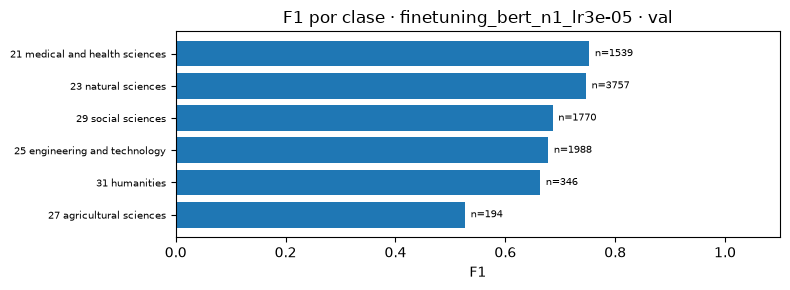

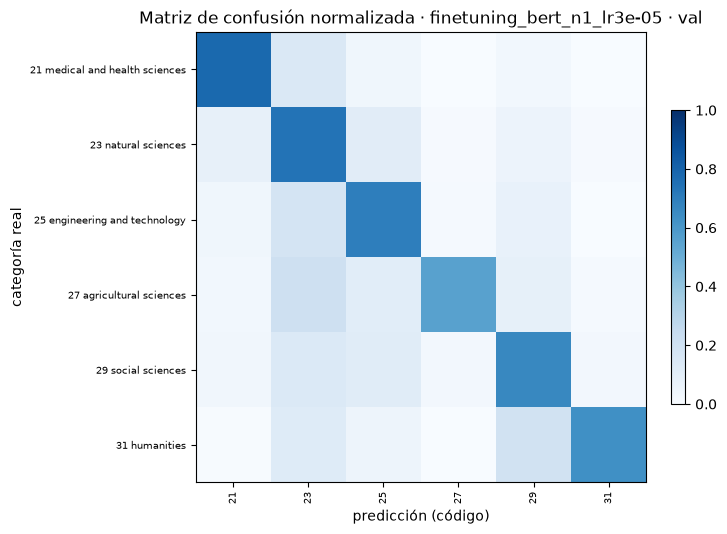

,finetuning_bert_n1_lr3e-05
proyectos,9594
errores,2735
% errores que son otra categoría válida del proyecto,62.3
accuracy estricta,0.7149
accuracy si contara cualquier categoría válida del proyecto,0.8925


,casos,real,predicha
6,413,23 natural sciences,25 engineering and technology
11,344,25 engineering and technology,23 natural sciences
5,301,23 natural sciences,21 medical and health sciences
21,243,29 social sciences,23 natural sciences
0,228,21 medical and health sciences,23 natural sciences
8,207,23 natural sciences,29 social sciences
22,202,29 social sciences,25 engineering and technology
13,146,25 engineering and technology,29 social sciences
10,76,25 engineering and technology,21 medical and health sciences
29,66,31 humanities,29 social sciences


In [11]:
EXPERIMENTO_ANALISIS = None   # p. ej. "finetuning_bert_n2_lr2e-05"; None = el mejor de cada nivel

def mejor_experimento(nivel):
    candidatos = {e: t for (e, n), t in predicciones.items() if n == nivel and not e.startswith("baseline")}
    if not candidatos:
        return None
    return max(candidatos, key=lambda e: f1_score(candidatos[e]["y_real"], candidatos[e]["y_pred"],
                                                 labels=clases_nivel[nivel], average="macro", zero_division=0))

def analizar_errores(experimento, nivel):
    tabla = predicciones[(experimento, nivel)].copy()
    clases = clases_nivel[nivel]
    etiqueta = {c: f"{c} {nombre_categoria.get(c, '?')}" for c in clases}

    # 1. Por clase
    informe = pd.DataFrame(classification_report(tabla["y_real"], tabla["y_pred"], labels=clases,
                                                 output_dict=True, zero_division=0)).T.loc[[str(c) for c in clases]]
    informe.index = [etiqueta[c] for c in clases]
    informe = informe.rename(columns={"support": "ejemplos"}).astype({"ejemplos": int}).sort_values("f1-score")
    informe.to_csv(RESULTADOS / f"por_clase_{experimento}_{CONJUNTO}.csv")
    display(informe.round(3))

    import matplotlib.pyplot as plt
    fig, ax = plt.subplots(figsize=(8, max(3, 0.28 * len(clases))))
    ax.barh(informe.index, informe["f1-score"])
    for y_pos, (f1, n) in enumerate(zip(informe["f1-score"], informe["ejemplos"])):
        ax.text(f1 + 0.01, y_pos, f"n={n}", va="center", fontsize=7)
    ax.set(xlabel="F1", xlim=(0, 1.1), title=f"F1 por clase · {experimento} · {CONJUNTO}")
    ax.tick_params(axis="y", labelsize=7)
    fig.tight_layout()
    fig.savefig(CARPETA_GRAFICAS / f"f1_por_clase_{experimento}_{CONJUNTO}.png", dpi=150)
    plt.show()

    # 2. Matriz de confusión normalizada por filas
    matriz = confusion_matrix(tabla["y_real"], tabla["y_pred"], labels=clases, normalize="true")
    lado = max(6, 0.3 * len(clases))
    fig, ax = plt.subplots(figsize=(lado + 1, lado))
    imagen = ax.imshow(matriz, cmap="Blues", vmin=0, vmax=1)
    ax.set_xticks(range(len(clases)), [str(c) for c in clases], rotation=90, fontsize=7)
    ax.set_yticks(range(len(clases)), [etiqueta[c][:40] for c in clases], fontsize=7)
    ax.set(xlabel="predicción (código)", ylabel="categoría real",
           title=f"Matriz de confusión normalizada · {experimento} · {CONJUNTO}")
    fig.colorbar(imagen, ax=ax, fraction=0.03)
    fig.tight_layout()
    fig.savefig(CARPETA_GRAFICAS / f"confusion_{experimento}_{CONJUNTO}.png", dpi=150)
    plt.show()

    # 3 y 4. Hermanas y categorías descartadas
    errores = tabla[tabla["y_real"] != tabla["y_pred"]].copy()
    errores["otra_categoria_del_proyecto"] = [
        pred in validas[nivel].loc[pid] for pid, pred in zip(errores["projectID"], errores["y_pred"])
    ]
    resumen = {"proyectos": len(tabla), "errores": len(errores),
               "% errores que son otra categoría válida del proyecto":
                   round(100 * errores["otra_categoria_del_proyecto"].mean(), 1),
               "accuracy estricta": round(1 - len(errores) / len(tabla), 4),
               "accuracy si contara cualquier categoría válida del proyecto":
                   round(1 - (~errores["otra_categoria_del_proyecto"]).sum() / len(tabla), 4)}
    if nivel == 2:
        errores["misma_raiz"] = errores["y_real"].map(raiz_de) == errores["y_pred"].map(raiz_de)
        frecuencia_pred = tabla["y_pred"].value_counts(normalize=True)
        esperado = []
        for real in errores["y_real"]:
            otras = frecuencia_pred.drop(real, errors="ignore")
            otras = otras / otras.sum()
            esperado.append(otras[[raiz_de[c] == raiz_de[real] for c in otras.index]].sum())
        resumen["% errores entre categorías hermanas (misma raíz)"] = round(100 * errores["misma_raiz"].mean(), 1)
        resumen["% esperado si el error fuese al azar"] = round(100 * np.mean(esperado), 1)
    display(pd.Series(resumen, name=experimento, dtype=object).to_frame())

    # Confusiones más frecuentes
    pares = (errores.groupby(["y_real", "y_pred"]).size().rename("casos").reset_index()
             .sort_values("casos", ascending=False).head(10))
    pares["real"] = pares["y_real"].map(etiqueta)
    pares["predicha"] = pares["y_pred"].map(etiqueta)
    if nivel == 2:
        pares["hermanas"] = pares["y_real"].map(raiz_de) == pares["y_pred"].map(raiz_de)
    display(pares.drop(columns=["y_real", "y_pred"]))
    errores.to_csv(RESULTADOS / f"errores_{experimento}_{CONJUNTO}.csv", index=False)
    return errores

errores_por_nivel = {}
for nivel in (2, 1):
    experimento = EXPERIMENTO_ANALISIS if EXPERIMENTO_ANALISIS and (EXPERIMENTO_ANALISIS, nivel) in predicciones \
        else mejor_experimento(nivel)
    if experimento is None:
        print(f"Nivel {nivel}: todavía no hay predicciones de modelos en {CONJUNTO}.")
        continue
    print(f"\n=== Nivel {nivel}: {experimento} ===")
    errores_por_nivel[nivel] = (experimento, analizar_errores(experimento, nivel))

In [12]:
# Ejemplos de errores para revisar a mano (semilla fija): título, real, predicha y si era otra categoría del proyecto
for nivel, (experimento, errores) in errores_por_nivel.items():
    print(f"\n=== Ejemplos de errores · nivel {nivel} · {experimento} ===")
    muestra_errores = errores.sample(min(5, len(errores)), random_state=SEMILLA)
    for fila in muestra_errores.itertuples():
        proyecto = info_proyectos.loc[fila.projectID]
        print(f"\n[{fila.projectID}] {proyecto['title']}")
        print(f"  real: {fila.y_real} {nombre_categoria.get(fila.y_real)} | "
              f"predicha: {fila.y_pred} {nombre_categoria.get(fila.y_pred)} | "
              f"otra categoría del proyecto: {'sí' if fila.otra_categoria_del_proyecto else 'no'}")
        print("  " + proyecto["summary"][:300].replace("\n", " ") + "…")


=== Ejemplos de errores · nivel 2 · finetuning_bert_n2_lr3e-05 ===

[754329] Investigations Supporting MOX Fuel Licensing in ESNII Prototype Reactors
  real: 43 physical sciences | predicha: 59 other engineering and technologies | otra categoría del proyecto: sí
  INSPYRE, a proposal fully supported and endorsed by the Steering Committee of the EERA Joint Programme on Nuclear Materials, focusses on the investigation of fast reactor MOX fuel to support the licensing of the start-up cores of the ESNII reactor prototypes. It will: • Use carefully designed separa…

[639211] Time-scale bridging potentials for realistic molecular dynamics simulations
  real: 51 mathematics | predicha: 43 physical sciences | otra categoría del proyecto: no
  The possibility to produce materials with ultra-strengths could revolutionize materials design. Since 80 years ultra-strength materials are known to exist only theoretically. Now, new experiments show that traditional believe can be overcome by nanostruc

## Para cerrar el trabajo

- Cuando Izan y Mónica suban `metricas_izan.csv` y `metricas_monica.csv`, y las predicciones de
  Izan con el mismo formato (`projectID, nivel, conjunto, y_real, y_pred`), basta con volver a
  ejecutar la sección "Comparación de resultados" para actualizar la tabla común, los intervalos,
  las comparaciones pareadas y el ranking por nivel.
- Con las decisiones cerradas: activar `EVALUAR_TEST` (una vez por nivel), cambiar
  `CONJUNTO = "test"` y repetir el análisis para el informe final.
- Integrar en el README los textos de Mónica e Izan y revisar las conclusiones entre los tres.